In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("dortmund_jasa.dat", sep = r"\s+", header = 0, index_col = 0)
print(df.head())

                unemployment  birth.death  moves.in.out  soc.ins.emp  \
City-Ost            2.163426     1.596534      0.441275     3.711335   
City-West           1.502882   -16.169153      3.359949     1.127376   
Cityring-Ost        1.187816     0.677955     -0.533034     5.569033   
Cityring-West       1.200776    -2.263297     -0.464626     3.365868   
Westfalenhalle     -0.097747     0.108169     -0.828727     3.255687   

                inhabitants  
City-Ost          -0.398488  
City-West         -1.446842  
Cityring-Ost      -0.270205  
Cityring-West     -0.809970  
Westfalenhalle     1.075703  


In [3]:
X = np.array(df)

ids = np.argmin(X[:,1])
ids
X2 = np.delete(X, ids, axis  =0)

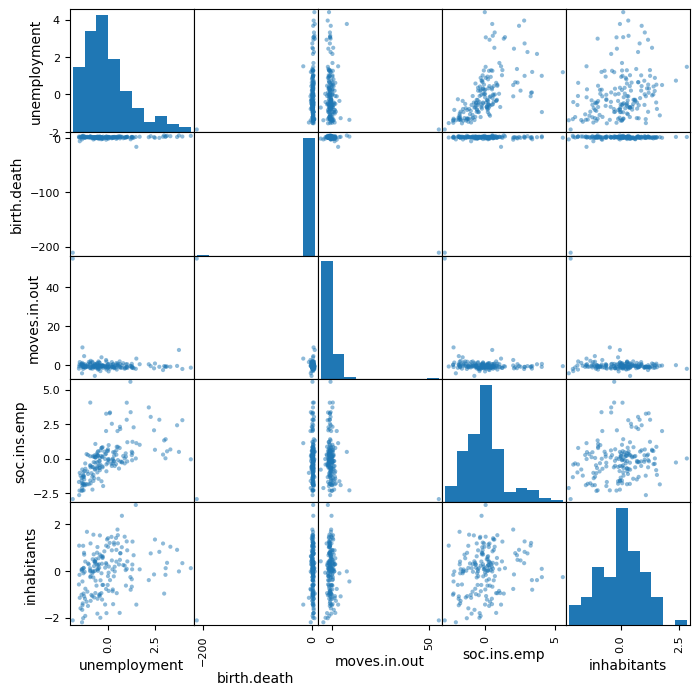

In [4]:
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
scatter_matrix(df, figsize = (8, 8))
plt.show()

In [5]:
from sklearn import metrics
from sklearn.metrics import adjusted_rand_score

In [6]:
#euclidean distance
def euclid_distance(p1, p2):
    return np.sqrt(np.sum((p1-p2)**2))

#functions for cluster assignment and cluster mean update
def assign_clusters(X, clusters):
    n = X.shape[0]
    for k in clusters:
        clusters[k]["points"] = []  # Clear points each iteration (moved here)

    for i in range(n):
        curr_X = X[i, :]
        dist = [euclid_distance(curr_X, clusters[k]["center"]) for k in clusters]
        curr_cluster = np.argmin(dist)
        clusters[curr_cluster]["points"].append(i)  # Store index instead of point
    return clusters

def update_clusters(X, clusters):
    for k in clusters:
        indices = clusters[k]["points"]
        if indices:  # Check non-empty
            cluster_members = X[indices]  # Get points by index
            updated_center = cluster_members.mean(axis=0)
            clusters[k]["center"] = updated_center
    return clusters

In [7]:
def initialization_heur(X1, sed):

    n, d = X1.shape
    np.random.seed(sed)
    indices = np.random.choice(n, 5, replace=False)
    centroids = X1[indices, :]
    c1 =  X1[indices, :]

    clusters = {0: {"center":c1[0,:], "points":[]},
                1: {"center":c1[1,:], "points":[]},
                2: {"center":c1[2,:], "points":[]},
                3: {"center":c1[3,:], "points":[]},
                4: {"center":c1[4,:], "points":[]}
               }
                

    clusters = assign_clusters(X1,clusters)
    clusters = update_clusters(X1,clusters)
    cov_initial1 = np.zeros((d, d))

    for i in clusters[0]["points"]:
        diff =  (X1[i] - clusters[0]["center"]).reshape((d, 1))
        cov_initial1+= (diff @ diff.T)/ len(clusters[0]["points"])

    cov_initial2 = np.zeros((d, d))
    for i in clusters[1]["points"]:
        diff =  (X1[i] - clusters[1]["center"]).reshape((d, 1))
        cov_initial2+= (diff @ diff.T)/ len(clusters[1]["points"])

    cov_initial3 = np.zeros((d, d))
    for i in clusters[2]["points"]:
        diff =  (X1[i] - clusters[2]["center"]).reshape((d, 1))
        cov_initial3+= (diff @ diff.T)/ len(clusters[2]["points"])
    
    cov_initial4 = np.zeros((d, d))
    for i in clusters[3]["points"]:
        diff =  (X1[i] - clusters[3]["center"]).reshape((d, 1))
        cov_initial4+= (diff @ diff.T)/ len(clusters[3]["points"])
    
    cov_initial5 = np.zeros((d, d))
    for i in clusters[4]["points"]:
        diff =  (X1[i] - clusters[4]["center"]).reshape((d, 1))
        cov_initial5+= (diff @ diff.T)/ len(clusters[4]["points"])
  
    
    covar = [cov_initial1, cov_initial2, cov_initial3, cov_initial4,cov_initial5]
    return centroids, covar

In [8]:
def heuristic_clustering(X1,see, K= 5, max_inner_iter= 500, tol=1e-4):

    n, d = X1.shape

    # ensure float64
    X1 = X1.astype(np.float64)


        # Initialization
    centroids, cov = initialization_heur(X1,see)
    centroids = centroids.astype(np.float64)
    Omega = [np.linalg.inv(c.astype(np.float64)+1e-6*np.eye(d)) for c in cov]
    
    prev_centroids = centroids.copy()
    est_clust_assignments = np.zeros(n, dtype=int)

    for m in range(max_inner_iter):
            #print(m)
            #  Assignment
            for i in range(n):
                dist = []

                for j in range(K):
                    const_term = ((1 / 2) ** d) * (1 / np.pi ** (d / 2)) \
                                 * (np.linalg.det(Omega[j]) ** 0.5) * (1 / n)

                    exp_term = (2 ** (1 - d / 2)) * (np.linalg.det(Omega[j]) ** 0.5) \
                               / (n * (np.pi ** (d / 2)))

                    diff = (X1[i] - centroids[j]).reshape((d, 1))
                    dist_val = const_term - exp_term * np.exp(
                        -0.5 * (diff.T @ Omega[j] @ diff)
                    )
                    dist.append(dist_val)

                est_clust_assignments[i] = np.argmin(dist)

            # Centroid & Covariance Update 
            for c in range(K):
                indices = np.where(est_clust_assignments == c)[0]
             
                if len(indices) == 0:
                    continue

                # differences
                diffs = [(X1[e] - centroids[c]).reshape((d, 1)) for e in indices]

                # log-domain exponents
                log_exponents = np.array([-0.5 * (diff.T @ Omega[c] @ diff).item() for diff in diffs], dtype=np.float64)

                # log-sum-exp trick for safe sum of weights
                max_log = np.max(log_exponents)
                sum_weights = np.sum(np.exp(log_exponents - max_log)) * np.exp(max_log)

                # compute exact original weights safely
                weights = np.exp(log_exponents)

                # Centroid update
                weighted_sum = np.zeros(d, dtype=np.float64)
                for w, diff, e in zip(weights, diffs, indices):
                    weighted_sum += w * Omega[c].dot(X1[e])
                centroids[c] = np.linalg.inv(Omega[c]) @ (weighted_sum / sum_weights)
                
                
                # differences
                diffs = [(X1[e] - centroids[c]).reshape((d, 1)) for e in indices]

                # log-domain exponents
                log_exponents = np.array([-0.5 * (diff.T @ Omega[c] @ diff).item() for diff in diffs], dtype=np.float64)

                # log-sum-exp trick for safe sum of weights
                max_log = np.max(log_exponents)
                sum_weights = np.sum(np.exp(log_exponents - max_log)) * np.exp(max_log)

                # compute exact original weights safely
                weights = np.exp(log_exponents)
                # Covariance update
                weighted_cov = np.zeros((d, d), dtype=np.float64)
                for w, diff in zip(weights, diffs):
                    weighted_cov += w * (diff @ diff.T)
                weighted_cov /= sum_weights
                weighted_cov += 1e-6 * np.eye(d)  # minimal regularization

                # Omega update
                Omega[c] = (np.trace(Omega[c] @ weighted_cov) / d) * np.linalg.pinv(weighted_cov)

            # Check convergence
            diff_centroids = np.linalg.norm(prev_centroids - centroids, axis=1)
            if np.all(diff_centroids < tol):
                break
            prev_centroids = centroids.copy()
        
    return est_clust_assignments, centroids, Omega#, np.linalg.inv(Omega)

In [9]:
def loss_val_cluster(Om_clus, data_all, ind_clus, mean_clus):
    num_ob, dim = data_all.shape
    
    p1 = (np.linalg.det(Om_clus)**(1/2) * len(ind_clus))/( ((np.pi)**(dim/2)) * (2**dim) * num_ob)
    p2 = 0
    for c1 in ind_clus:
        differ = (data_all[c1] - mean_clus).reshape((dim,1))
        p2+=np.exp(-0.5 * (differ.T @ Om_clus @ differ))
    p2 *= (2/num_ob) * (1/(2 * np.pi)**(dim/2)) * np.linalg.det(Om_clus)**(1/2)
    return (p1- p2)

In [10]:
n_iter = 1000
loss_overall = float("inf")

for it in range(n_iter):
    est_assign, cent, om = heuristic_clustering(X2, it)
    loss_all = 0
    for h in range(5):
        loss_all+=loss_val_cluster(om[h], X2, np.where(est_assign == h)[0], cent[h]).item()
    if loss_all < loss_overall:
        loss_overall = loss_all
        best_assign = est_assign
        best_cent = cent
        best_omega = om

In [11]:
loss_overall# k = 6: -146299147322.24142
#k = 5 : -216756069294.20407
# for k = 4 :-216756069294.2038
# for k = 3 :-146299102664.66882



-218038675981.13004

In [12]:
print(best_assign)
print(best_omega)
print(best_cent)

[0 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 0 0 2 0 0 0 0 0
 2 0 0 0 0 0 2 0 2 2 0 2 0 2 2 0 0 0 0 0 0 0 0 2 1 0 0 0 0 2 0 0 0 0 0 0 0
 0 2 0 0 2 0 2 2 2 2 2 0 0 2 2 2 2 1 2 0 2 0 0 0 0 0 2 2 2 2 2 2 2 2 0 0 0
 0 2 0 1 0 0 2 0 0 0 2 0 2 2 0 4 2 2 0 2 0 0 0 0 2 0 0 2 0 0 0 0 0 2 0 2 0
 0 0 0 0 0 0 0 0 2 0 0 2 0 0 0 0 2 0 0 0 0]
[array([[ 1.78659574, -0.75612464,  0.41954112,  0.17776128, -0.4000884 ],
       [-0.75612464,  1.47989469, -0.26660124,  0.66203934,  0.23461613],
       [ 0.41954112, -0.26660124,  1.01072783,  0.16630517, -0.01872238],
       [ 0.17776128,  0.66203934,  0.16630517,  3.10862184,  0.17426664],
       [-0.4000884 ,  0.23461613, -0.01872238,  0.17426664,  0.63103219]]), array([[214423.77364137, -68055.27216539,  -6056.21799322,
        -24802.50430673, -37609.87631646],
       [-68055.27216658,  66995.40403476, -36148.12563581,
         23131.4527601 , -74135.73043434],
       [ -6056.21799144, -36148.12563654, 227151.80546551,
         53469.13048

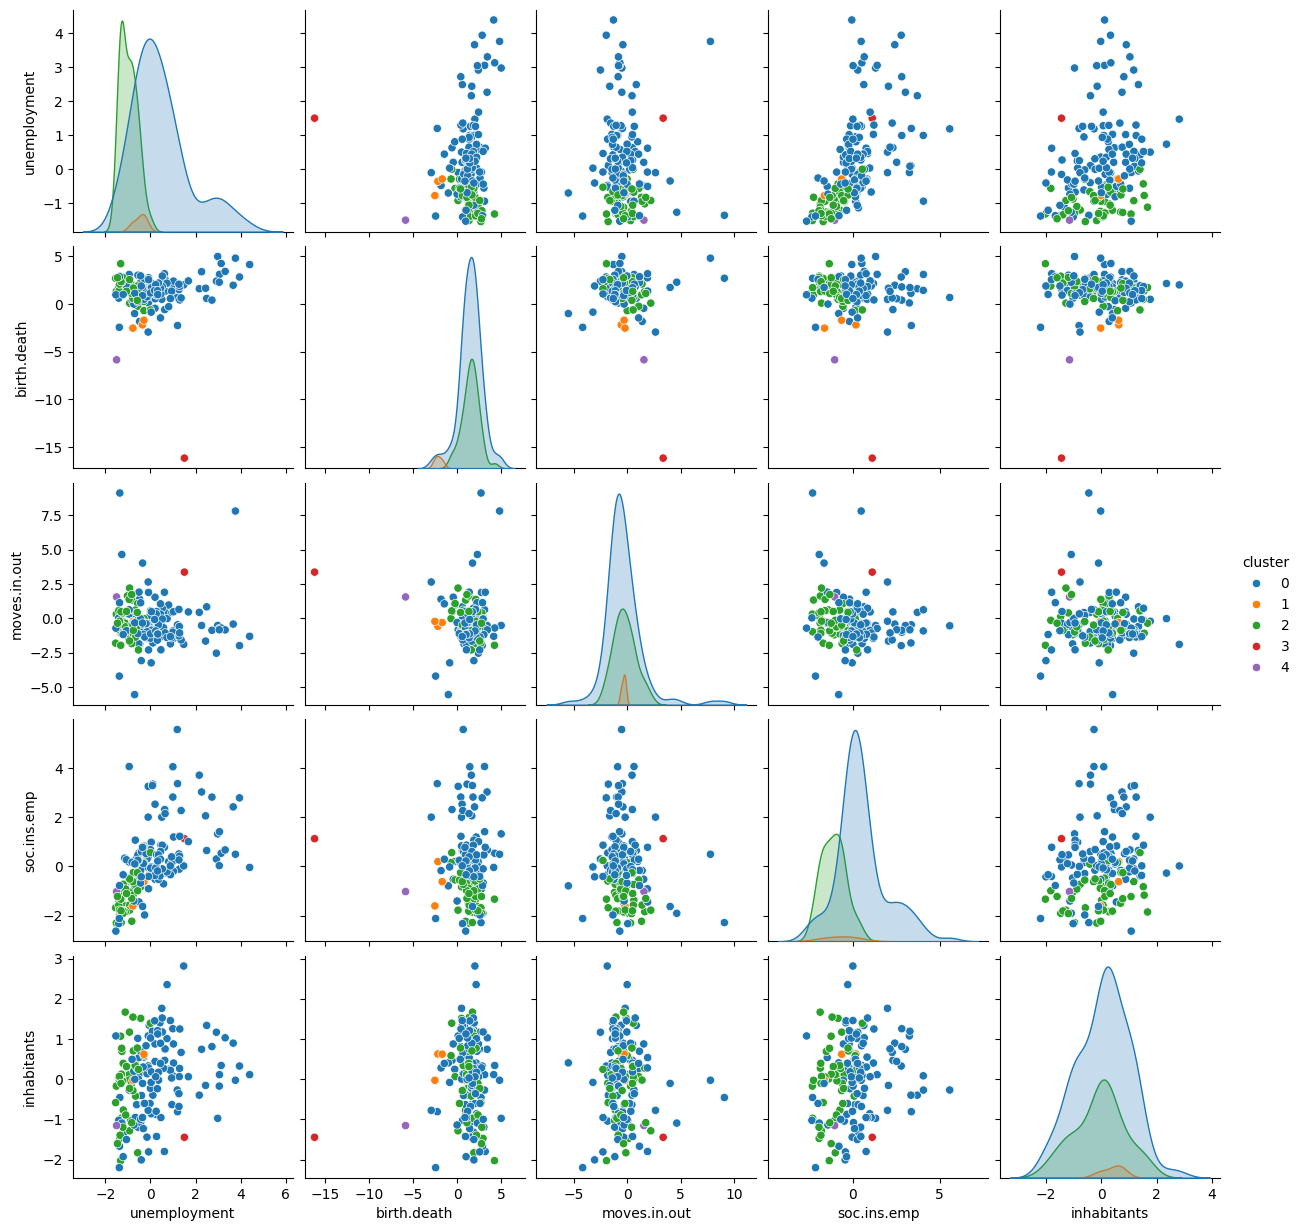

In [13]:
import seaborn as sns

df_plot = df.copy()
df_plot = df_plot.drop(df_plot.index[ids])
df_plot["cluster"] = best_assign

sns.pairplot(df_plot, hue="cluster", palette="tab10")
plt.show()

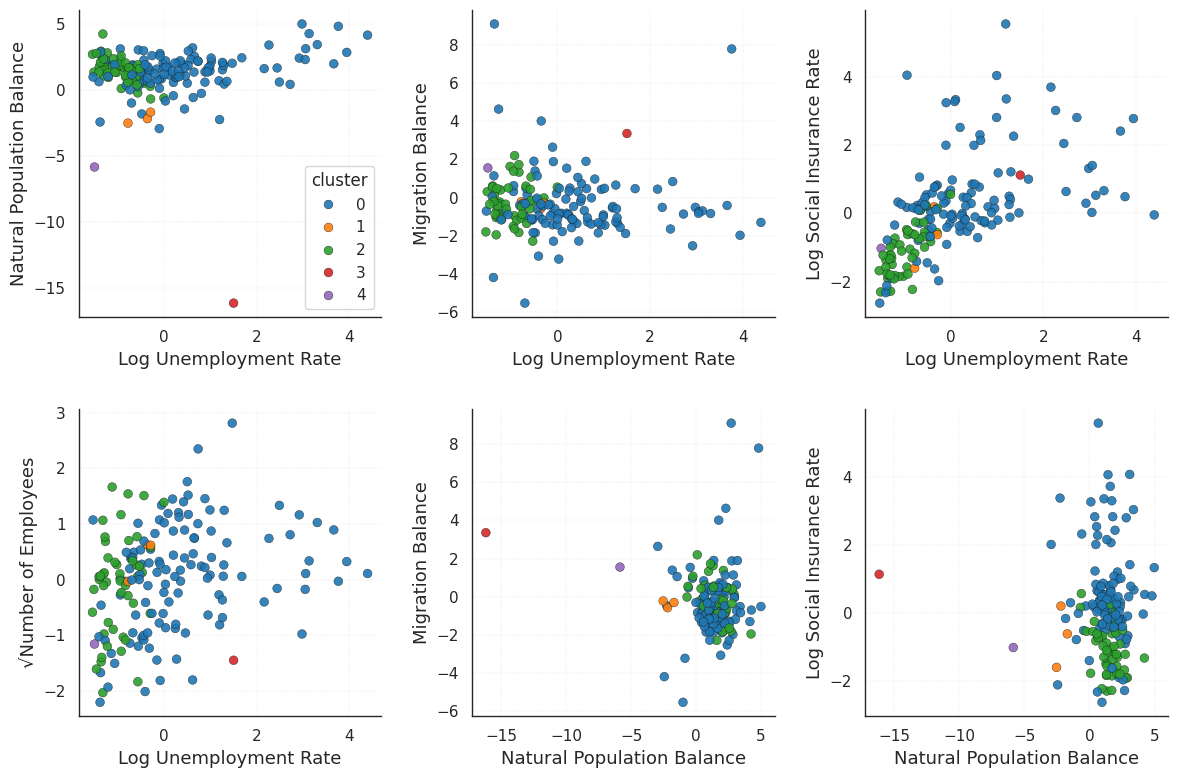

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

# -----------------------
# 1. Styling
# -----------------------
sns.set_theme(style="white")

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 1,
})

# -----------------------
# 2. Prepare data
# -----------------------
df_plot = df.copy()
df_plot = df_plot.drop(df_plot.index[ids])  # remove the row

# Optional: rename columns for nicer labels
df_custom = df_plot.copy()
df_custom.columns = [
    'Log Unemployment Rate',
    'Natural Population Balance',
    'Migration Balance',
    'Log Social Insurance Rate',
    '√Number of Employees'
]

features = df_custom.columns[:5]  # only feature columns
df_custom["cluster"] = best_assign          # add cluster assignments

# Generate pairs (like scatter matrix)
pairs = list(itertools.combinations(features, 2))
max_plots = 6
pairs = pairs[:max_plots]

# Layout
ncols = 3
nrows = 2
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 8))
axes = axes.flatten()

# -----------------------
# 3. Plot
# -----------------------
for idx, ((x_var, y_var), ax) in enumerate(zip(pairs, axes)):

    # Scatterplot for clusters
    sns.scatterplot(
        data=df_custom,
        x=x_var,
        y=y_var,
        hue="cluster",
        palette="tab10",
        s=40,
        edgecolor="k",
        linewidth=0.3,
        alpha=0.9,
        ax=ax,
        legend=(idx == 0)  # only show legend on first subplot
    )

    # Optional: clean overlay for outliers if column exists
    if "outlier" in df_custom.columns:
        sns.scatterplot(
            data=df_custom[df_custom["outlier"]],
            x=x_var,
            y=y_var,
            ax=ax,
            facecolors='none',
            edgecolor='black',
            s=60,
            linewidth=0.8,
            marker='o',
            legend=False,
            zorder=10
        )

    # Labels
    ax.set_xlabel(x_var)
    ax.set_ylabel(y_var)

    # Clean look
    sns.despine(ax=ax)
    ax.grid(True, linestyle='--', linewidth=0.3, alpha=0.5)

# -----------------------
# 4. Remove unused axes
# -----------------------
for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

# -----------------------
# 5. Layout adjustments
# -----------------------
plt.tight_layout()
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# -----------------------
# 6. Save and show
# -----------------------
plt.savefig("clusters_dortmund.pdf", bbox_inches="tight")
plt.show()

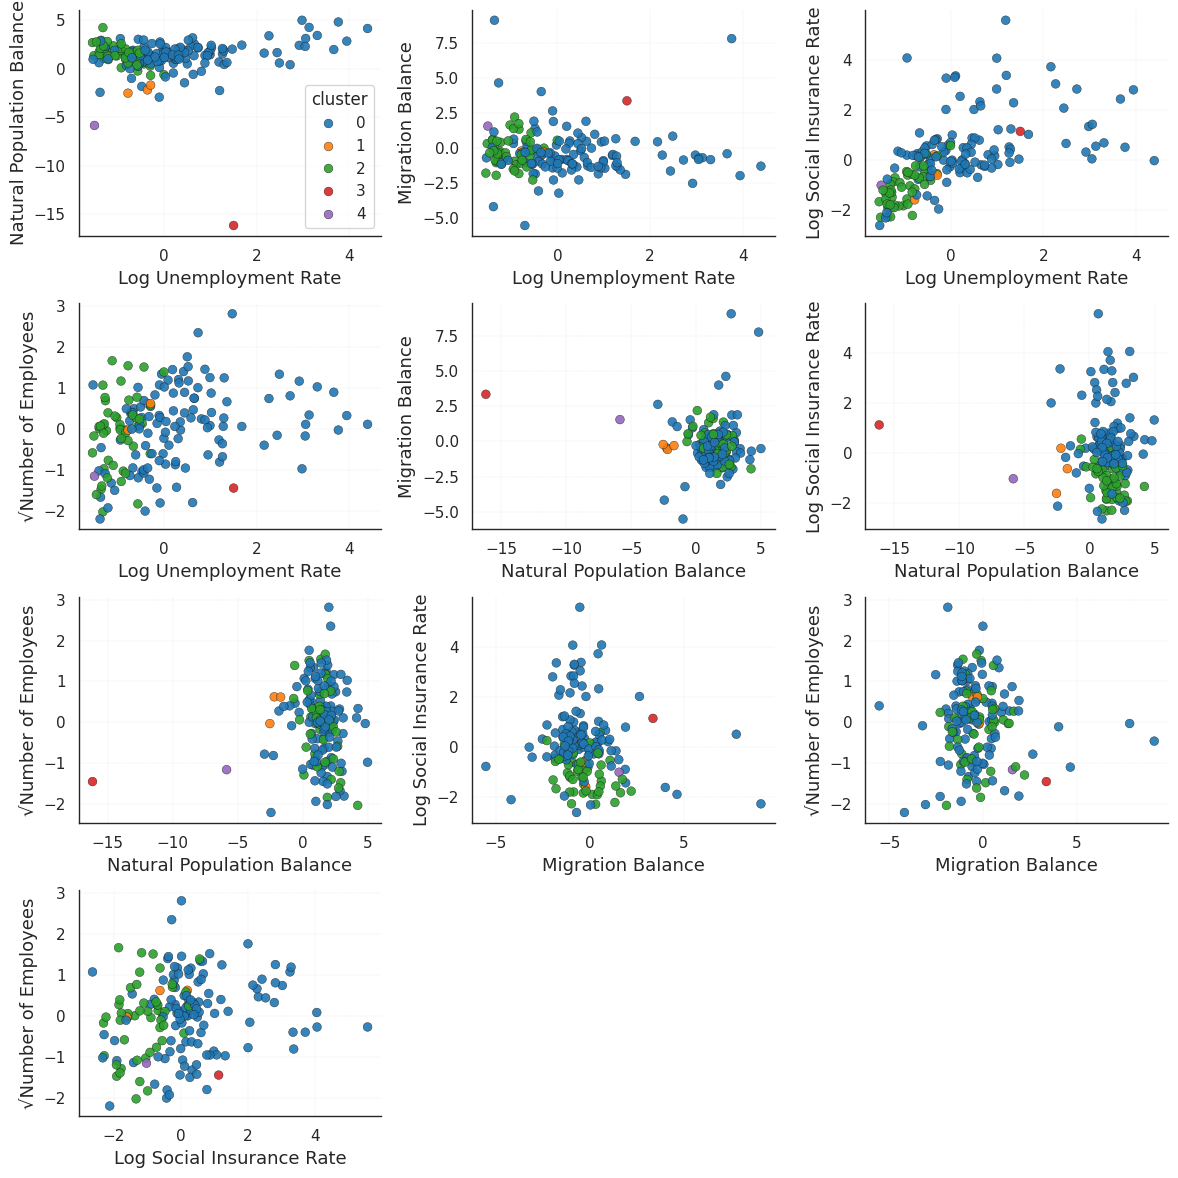

In [21]:
import math

# Generate all pairs of features
features = df_custom.columns[:5]
pairs = list(itertools.combinations(features, 2))
n_pairs = len(pairs)  # 10 in this case

# Determine grid layout dynamically
ncols = 3
nrows = math.ceil(n_pairs / ncols)  # round up
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*3))
axes = axes.flatten()

# Plot all pairs
for idx, ((x_var, y_var), ax) in enumerate(zip(pairs, axes)):
    sns.scatterplot(
        data=df_custom,
        x=x_var,
        y=y_var,
        hue="cluster",
        palette="tab10",
        s=40,
        edgecolor="k",
        linewidth=0.3,
        alpha=0.9,
        ax=ax,
        legend=(idx == 0)
    )
    ax.set_xlabel(x_var)
    ax.set_ylabel(y_var)
    sns.despine(ax=ax)
    ax.grid(True, linestyle='--', linewidth=0.3, alpha=0.5)

# Remove any unused axes (if grid has extra cells)
for j in range(len(pairs), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.subplots_adjust(wspace=0.3, hspace=0.3)
plt.savefig("clusters_dortmund.pdf", bbox_inches="tight")
plt.show()

In [14]:
import numpy as np

n_iter, n_obs = assignments_obs.shape
coassoc = np.zeros((n_obs, n_obs))

for it in range(n_iter):
    labels = assignments_obs[it]
    coassoc += (labels[:, None] == labels[None, :])

coassoc /= n_iter

NameError: name 'assignments_obs' is not defined

In [ ]:
from sklearn.cluster import AgglomerativeClustering

consensus = AgglomerativeClustering(
    n_clusters=4,   # choose your K
    metric='precomputed',
    linkage='average'
)

final_label = consensus.fit_predict(1 - coassoc)

In [ ]:
final_label

In [ ]:
ref_labels = assignments_obs[0,:]

In [ ]:
#final_labels

In [ ]:
from sklearn.metrics import confusion_matrix
from scipy.optimize import linear_sum_assignment
import numpy as np

def align_labels(ref_labels, new_labels):
    cm = confusion_matrix(ref_labels, new_labels)

    # Hungarian algorithm (maximize agreement)
    row_ind, col_ind = linear_sum_assignment(-cm)

    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    aligned = np.array([mapping[label] for label in new_labels])

    return aligned

aligned_assignments = np.zeros_like(assignments_obs)

aligned_assignments[0] = ref_labels

for it in range(1, n_iter):
    aligned_assignments[it] = align_labels(ref_labels,
                                           assignments_obs[it])

from scipy.stats import mode

result = mode(aligned_assignments, axis=0, keepdims=False)
final_labels = result.mode

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(final_label, final_labels)
nmi = normalized_mutual_info_score(final_label, final_labels)

print("ARI:", ari)
print("NMI:", nmi)